In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
# Настройка базовой директории данных
DATA_DIR = Path("../data/raw")

# 1. Загрузка каталога товаров
items_path = DATA_DIR / "dataset/small/marketplace/items.pq"
df_items = pd.read_parquet(items_path)

# 2. Загрузка справочника пользователей
users_path = DATA_DIR / "dataset/full/users.pq"
df_users = pd.read_parquet(users_path)

In [2]:
EVENTS_DIR = DATA_DIR / "dataset" / "small" / "marketplace" / "events"
event_files = sorted(EVENTS_DIR.glob("*.pq"))

# ------- Загрузка событий -------
SAMPLE = False          # True = сэмпл (быстро)
N_SAMPLE = 13000000    # размер сэмпла, если SAMPLE=True

if SAMPLE:
    df = ds.dataset(EVENTS_DIR, format="parquet").head(N_SAMPLE).to_pandas()
else:
    df = pd.concat([pd.read_parquet(f) for f in event_files], ignore_index=True)

# Экономия памяти: низкокардинальные строки -> category
for col in ["action_type", "subdomain", "os"]:
    df[col] = df[col].astype("category")

# День активности (timestamp лежит как timedelta[us])
df["day"] = df["timestamp"].dt.days

print("events shape:", df.shape)
print("уникальных пользователей:", df["user_id"].nunique())
df.head()


events shape: (130447117, 7)
уникальных пользователей: 1616763


,timestamp,user_id,item_id,subdomain,action_type,os,day
0,1082 days 00:00:00.089901,59328774,nfmcg_14777696,u2i,view,android,1082
1,1082 days 00:00:00.163483,66295302,nfmcg_26098539,catalog,view,android,1082
2,1082 days 00:00:00.864625,37542104,nfmcg_10840247,u2i,view,android,1082
3,1082 days 00:00:00.889192,35193548,nfmcg_8040572,catalog,view,android,1082
4,1082 days 00:00:00.936008,27256137,nfmcg_6770239,catalog,view,android,1082


# Анализ пользовательских данных T-ECD

In [3]:
# Общие агрегаты по пользователю
g = df.groupby("user_id")
df_users = g.agg(
    events=("item_id", "size"),        # всего действий
    unique_items=("item_id", "nunique"),  # уникальных товаров
    active_days=("day", "nunique"),    # дней активности
).reset_index()

# Число действий каждого типа
act = df.groupby(["user_id", "action_type"], observed=True).size().unstack(fill_value=0)
df_users = df_users.merge(act, on="user_id", how="left")

# Добавим отсутствующие типы действий нулями
for a in ["view", "click", "clickout", "like"]:
    if a not in df_users:
        df_users[a] = 0

# Доля переходов из просмотров
df_users["click_rate"] = df_users["click"] / df_users["view"].replace(0, np.nan)

# Приводим счётчики к int
for c in ["events", "unique_items", "active_days", "view", "click", "clickout", "like"]:
    df_users[c] = df_users[c].astype(int)

print("users shape:", df_users.shape)
df_users.head()

users shape: (1616763, 9)


,user_id,events,unique_items,active_days,click,clickout,like,view,click_rate
0,3,6,6,2,0,0,0,6,0.0
1,68,4,4,1,0,0,0,4,0.0
2,76,12,9,2,0,0,0,12,0.0
3,188,22,16,6,0,0,0,22,0.0
4,222,41,31,9,0,0,0,41,0.0


In [4]:
df_users.describe(include='all')
# Самые активные пользователи
df_users.sort_values("events", ascending=False).head(10)

,user_id,events,unique_items,active_days,click,clickout,like,view,click_rate
269345,14968784,2545,582,40,46,17,0,2482,0.018533
643311,35768329,2536,482,31,69,10,2,2455,0.028106
533260,29677064,2349,393,24,36,6,0,2307,0.015605
467869,26039598,2244,1125,74,22,4,34,2184,0.010073
936458,52105287,2236,1221,21,183,57,5,1991,0.091914
924454,51445432,2222,593,44,66,2,0,2154,0.030641
928035,51642284,2191,1682,59,51,4,0,2136,0.023876
1089312,60607048,2190,1403,11,82,2,5,2101,0.039029
1099333,61159143,2186,413,32,51,0,0,2135,0.023888
686311,38156757,2179,1290,22,93,19,0,2067,0.044993


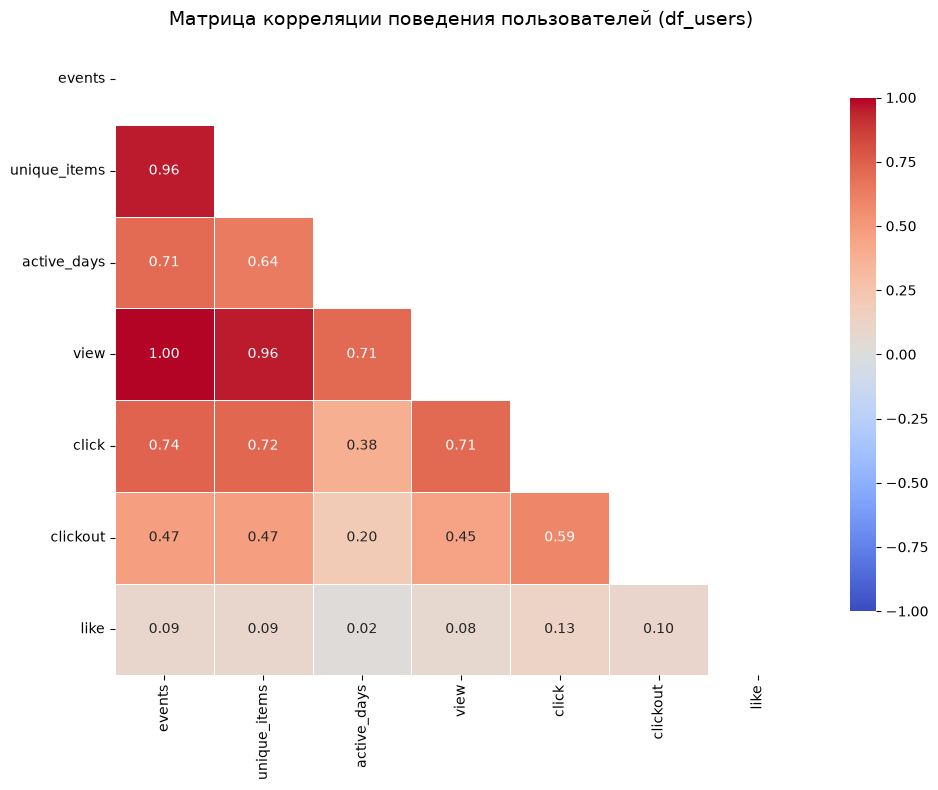

In [5]:
# 1. Отбираем только числовые колонки для анализа
columns_to_corr = [
    "events",
    "unique_items",
    "active_days",
    "view",
    "click",
    "clickout",
    "like",
]

df_corr = df_users[columns_to_corr]

# Считаем матрицу корреляции Пирсона
corr_matrix = df_corr.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))

# Строим тепловую карту
sns.heatmap(
    corr_matrix,
    mask=mask,  
    annot=True,  
    cmap="coolwarm", 
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title("Матрица корреляции поведения пользователей (df_users)", fontsize=14)
plt.tight_layout()
plt.show()


Анализ
Большинство событий это просмотр, что логично (корреляция между событием и просмотром равна 1)
Из-за корреляции между событиеями , уникальными вещами и просмотрами следует, что чем больше пользователь смотрит и чем больше уникальных товаров встречает, тем пропорционально больше он кликает.
По внешним ссылкам зачастую идет тот, кто и так много кликает 
Лайк к сожаелин. ни связан почти ни с чем. Немного с кликом.
Пользователи не зацикливаются на одних и тех же объектах. Чем больше они совершают действий, тем шире их кругозор (они постоянно открывают для себя новые item_id).
Регулярность посещения платформы увеличивает просмотры, но не гарантирует, что пользователь будет активно кликать

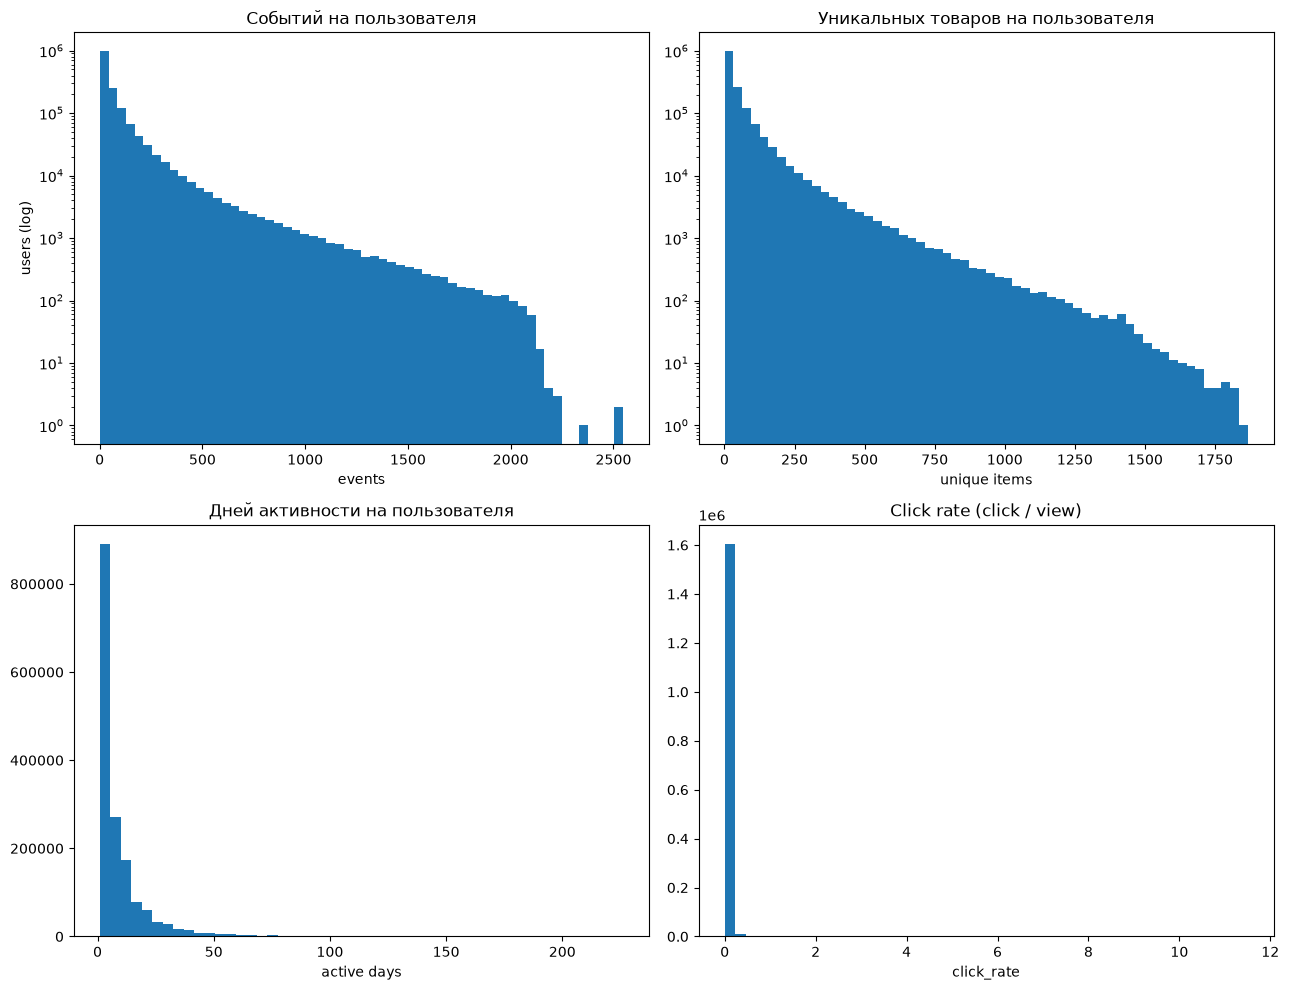

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].hist(df_users["events"], bins=60, log=True)
axes[0, 0].set_title("Событий на пользователя")
axes[0, 0].set_xlabel("events")
axes[0, 0].set_ylabel("users (log)")

axes[0, 1].hist(df_users["unique_items"], bins=60, log=True)
axes[0, 1].set_title("Уникальных товаров на пользователя")
axes[0, 1].set_xlabel("unique items")

axes[1, 0].hist(df_users["active_days"], bins=50)
axes[1, 0].set_title("Дней активности на пользователя")
axes[1, 0].set_xlabel("active days")

axes[1, 1].hist(df_users["click_rate"].dropna(), bins=50)
axes[1, 1].set_title("Click rate (click / view)")
axes[1, 1].set_xlabel("click_rate")

plt.tight_layout()
plt.show()


Анализ
Видны вылеты и есть польщователи с очень большим колдичеством посещений.
Огромный перекос данных : Подавляющее большинство из 1.6 млн пользователей заходят всего на 1–5 дней, совершают минимум действий и почти не кликают. На графиках они формируют гигантские пики слева.
Ломающий вылет в Click Rate: На графике CTR ось X растянута до 12. Это технический баг: у некоторых пользователей кликов зафиксировано больше, чем просмотров (деление на ноль или мелкие числа). В норме CTR не может быть больше 1.
На верхних графиках (События и Товары) виден резкий, неестественный срез в районе 2100 действий и 1850 товаров. После него идут пустые промежутки и одиночные точки-выбросы. Это говорит либо об ограничении при выгрузке данных, либо об активности ботов.
«Тяжелый хвост» в днях активности: Хотя большинство пользователей «однодневки», график растянут до 225+ дней из-за редких, но сверхактивных лояльных пользователей (ну или что то считывает статистики парсит сайт).

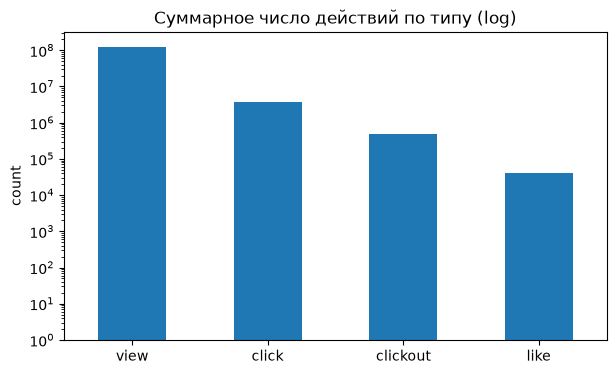

In [7]:
act_cols = ["view", "click", "clickout", "like"]
ax = df_users[act_cols].sum().plot(kind="bar", figsize=(7, 4), rot=0, log=True)
ax.set_title("Суммарное число действий по типу (log)")
ax.set_ylabel("count")
plt.show()

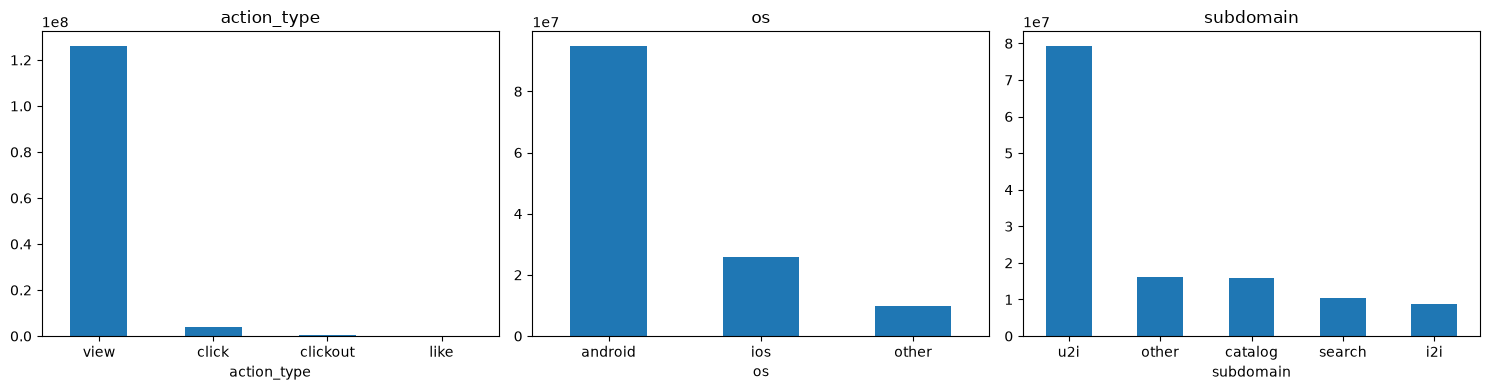

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["action_type"].value_counts().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("action_type")

df["os"].value_counts().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("os")

df["subdomain"].value_counts().plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("subdomain")

plt.tight_layout()
plt.show()

Анализ
Идет равномерное падение конверсии от просмотра до лайка.
Андройд генерирует большу часть конверсии
Лучше всего работает персональыне рекомендации.
i2i дает очень мало прироста

# Предлагаемые проепроцессинг пользователей

In [9]:
# Предпологаемый обработчик вылетов на основе анализа выше
# 1. Логическая очистка: убираем технический баг, где кликов больше, чем просмотров
# Также убираем NaN (пользователей без единого просмотра), чтобы не ломать графики
df_logical_clean = df_users[
    (df_users["click_rate"] <= 1.0) & (df_users["click_rate"].notna())
].copy()

# 2. Расчет порогов 99-го перцентиля для отсечения экстремальных хвостов (ботов/парсеров)
events_threshold = df_logical_clean["events"].quantile(0.99)
items_threshold = df_logical_clean["unique_items"].quantile(0.99)
days_threshold = df_logical_clean["active_days"].quantile(0.99)

print("--- Пороги отсечения (Топ-1% пользователей) ---")
print(f"Максимум действий (events): {events_threshold:.0f}")
print(f"Максимум уник. товаров (unique_items): {items_threshold:.0f}")
print(f"Максимум дней активности (active_days): {days_threshold:.0f}\n")

# 3. Фильтрация датасета
df_users_clean = df_logical_clean[
    (df_logical_clean["events"] <= events_threshold)
    & (df_logical_clean["unique_items"] <= items_threshold)
    & (df_logical_clean["active_days"] <= days_threshold)
]

# 4. Проверка результатов очистки
initial_rows = df_users.shape[0]
final_rows = df_users_clean.shape[0]
removed_rows = initial_rows - final_rows
removed_percent = (removed_rows / initial_rows) * 100

print("--- Результаты фильтрации выбросов ---")
print(f"Пользователей до очистки: {initial_rows:,}")
print(f"Пользователей после очистки: {final_rows:,}")
print(f"Удалено аномалий: {removed_rows:,} ({removed_percent:.2f}%)")

--- Пороги отсечения (Топ-1% пользователей) ---
Максимум действий (events): 841
Максимум уник. товаров (unique_items): 494
Максимум дней активности (active_days): 73

--- Результаты фильтрации выбросов ---
Пользователей до очистки: 1,616,763
Пользователей после очистки: 1,585,292
Удалено аномалий: 31,471 (1.95%)


# Анализ товарных даных T-ECD

In [10]:
# Агрегаты событий по товару
g = df.groupby("item_id")
df_items_stats = g.agg(
    events=("user_id", "size"),          # суммарная популярность (взаимодействий)
    unique_users=("user_id", "nunique"), # сколько разных пользователей видело товар
).reset_index()

# Число действий каждого типа на товар
act = df.groupby(["item_id", "action_type"], observed=True).size().unstack(fill_value=0)
df_items_stats = df_items_stats.merge(act, on="item_id", how="left")

for a in ["view", "click", "clickout", "like"]:
    if a not in df_items_stats:
        df_items_stats[a] = 0

# Доля переходов из просмотров
df_items_stats["click_rate"] = df_items_stats["click"] / df_items_stats["view"].replace(0, np.nan)

for c in ["events", "unique_users", "view", "click", "clickout", "like"]:
    df_items_stats[c] = df_items_stats[c].astype(int)

# Присоединяем каталог (категория / подкатегория / бренд / цена)
df_items_stats = df_items_stats.merge(df_items, on="item_id", how="left")

print("items stats shape:", df_items_stats.shape)
df_items_stats.head()


items stats shape: (2325409, 13)


,item_id,events,unique_users,click,clickout,like,view,click_rate,brand_id,category,subcategory,price,embedding
0,nfmcg_10000001,11,6,2,0,0,9,0.222222,137356,NaN,NaN,6.063640,"[-0.070853, 0.03246, 0.009126, 0.037786, -0.00..."
1,nfmcg_10000012,5,2,0,0,0,5,0.000000,53389,NaN,NaN,0.960436,"[-0.091099, 0.043168, -0.027675, 0.031663, -0...."
2,nfmcg_1000002,1,1,0,0,0,1,0.000000,34153,"Fashion Accessories, Tech Add-ons, and Style E...","Hats, Scarves, and Shawls",-1.793113,"[-0.056533, 0.082878, -0.063816, 0.095534, -0...."
3,nfmcg_10000034,2,2,0,0,0,2,0.000000,39543,NaN,NaN,3.416755,"[-0.112588, 0.043333, 0.029613, -0.004024, -0...."
4,nfmcg_10000039,3,1,0,0,1,2,0.000000,82320,"Fashion Accessories, Tech Add-ons, and Style E...",Jewelry and Costume Jewelry,4.293433,"[-0.157201, 0.026234, 0.00575, 0.069728, -0.10..."


In [11]:
df_items_stats.describe()

# Самые популярные товары
df_items_stats.sort_values("events", ascending=False).head(10)[
    ["item_id", "events", "unique_users", "click_rate", "category", "subcategory", "price"]
]

,item_id,events,unique_users,click_rate,category,subcategory,price
2000694,nfmcg_6396015,1346072,461600,0.053640,Children's Products and Childcare Items,Children's Games and Toys,1.724729
2217260,nfmcg_8797298,1301824,524759,0.046070,Miscellaneous Goods (Uncategorized),NaN,4.558963
731222,nfmcg_18106422,1239029,442442,0.040014,Miscellaneous Goods (Uncategorized),NaN,1.655624
2084752,nfmcg_7326721,1099535,423079,0.033496,Electronic Devices and Gadgets,PCs and Peripheral Devices,5.317933
597165,nfmcg_16621063,693366,315787,0.014393,"Cosmetics, Personal Care, and Health Maintenan...",Perfumes and Aromatic Products,1.597694
2232087,nfmcg_8961427,659955,313131,0.025425,Home/Office Furniture and Interior Decor,Kitchen Sets and Interior Elements,2.619599
1568483,nfmcg_27366316,646818,281983,0.033562,Electronic Devices and Gadgets,TV Panels and Components,8.402068
2231767,nfmcg_8957656,640653,314608,0.051979,Miscellaneous Goods (Uncategorized),NaN,0.786800
844012,nfmcg_19353812,622417,233192,0.022539,"Construction and Renovation Materials, Tools, ...",Hand and Power Tools,2.222647
800350,nfmcg_1887189,607782,309186,0.012411,"Automotive Accessories, Spare Parts, and Car C...",Automotive Products and Accessories,-5.684236


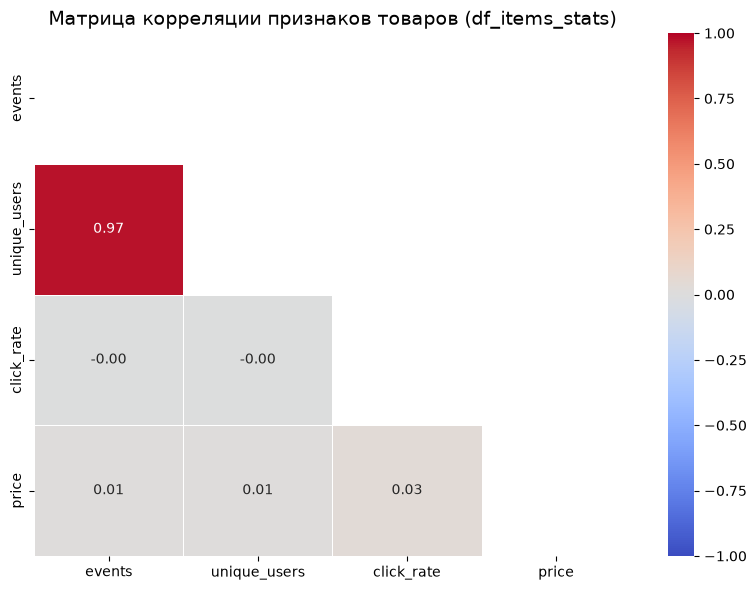

In [ ]:
# 1. Отбираем числовые признаки товара для корреляции
# Категориальные (category, subcategory) и ID (item_id) исключаем
columns_for_items_corr = ["events", "unique_users", "click_rate", "price"]

# Если в df_items_stats есть другие числовые фичи, они тоже подойдут
df_items_corr = df_items_stats[columns_for_items_corr]

# 2. Считаем матрицу корреляции Пирсона
items_corr_matrix = df_items_corr.corr()

# 3. Настраиваем маску, чтобы не дублировать половинки графика
mask = np.triu(np.ones_like(items_corr_matrix, dtype=bool))

# 4. Строим график
plt.figure(figsize=(8, 6))
sns.heatmap(
    items_corr_matrix,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title("Матрица корреляции признаков товаров (df_items_stats)", fontsize=14)
plt.tight_layout()
plt.show()


Анализ 
Есть лишь зависимость количества уникальных пользователей и событий, что очевидно , так как чем больше уникальных пользователей тем больше событий. Растем в ширь получается

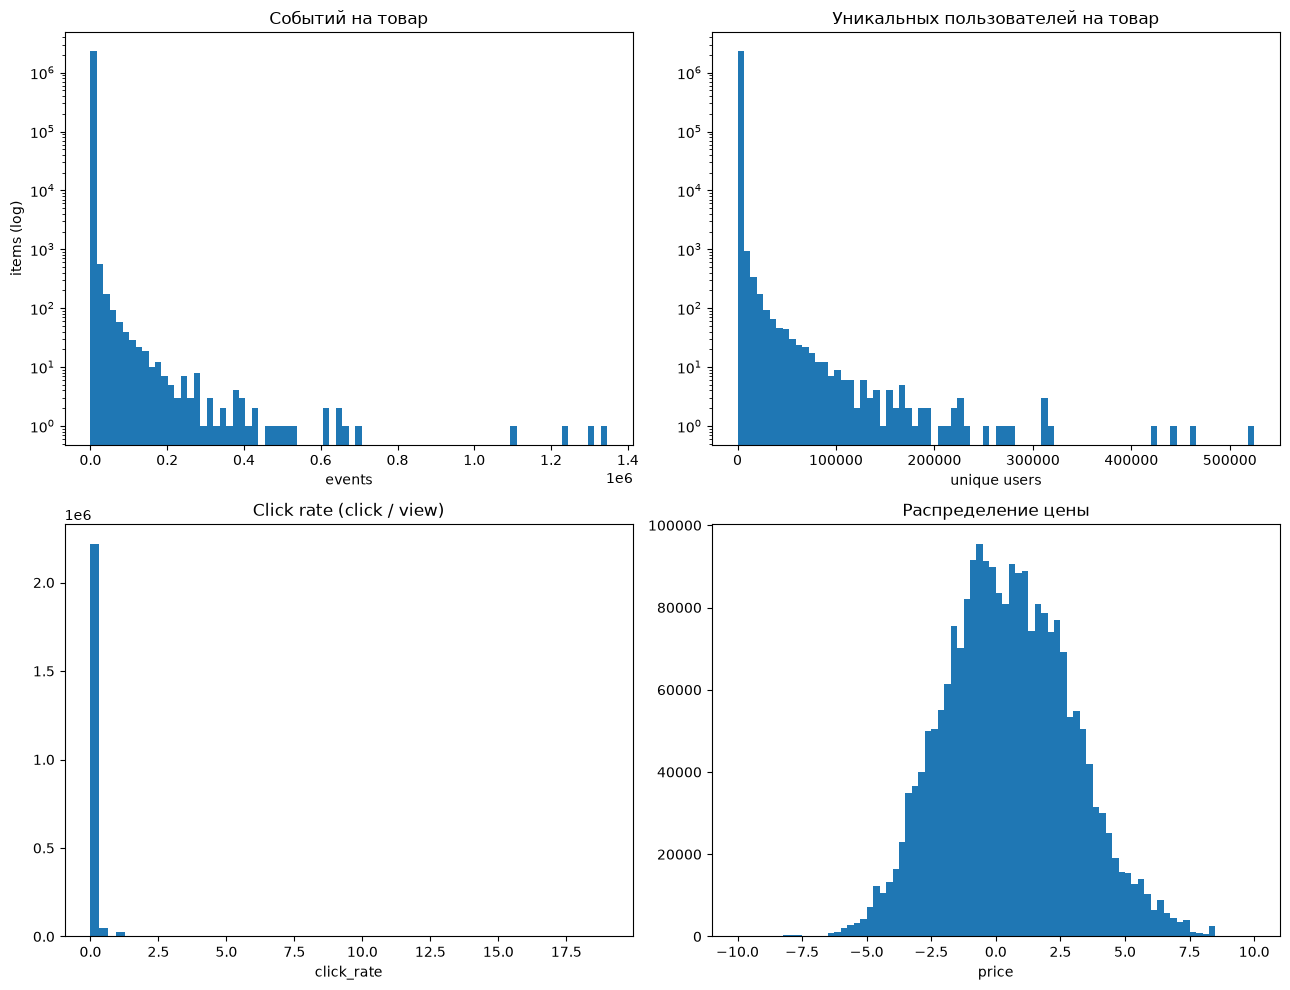

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].hist(df_items_stats["events"], bins=80, log=True)
axes[0, 0].set_title("Событий на товар")
axes[0, 0].set_xlabel("events")
axes[0, 0].set_ylabel("items (log)")

axes[0, 1].hist(df_items_stats["unique_users"], bins=80, log=True)
axes[0, 1].set_title("Уникальных пользователей на товар")
axes[0, 1].set_xlabel("unique users")

axes[1, 0].hist(df_items_stats["click_rate"].dropna(), bins=60)
axes[1, 0].set_title("Click rate (click / view)")
axes[1, 0].set_xlabel("click_rate")

axes[1, 1].hist(df_items_stats["price"].dropna(), bins=80)
axes[1, 1].set_title("Распределение цены")
axes[1, 1].set_xlabel("price")

plt.tight_layout()
plt.show()


Анализ
Цела уже была нормализованна скорее всего
Click rate аналогичная проблема с пользователями
Очень тяжелые хвосты в событиях и пользователях. Много холодных товаров.

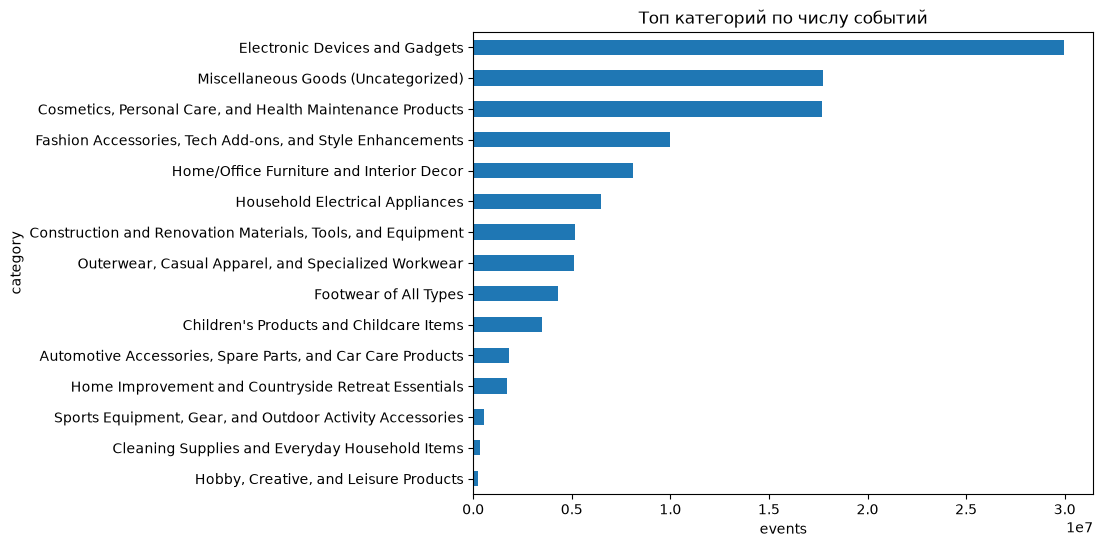

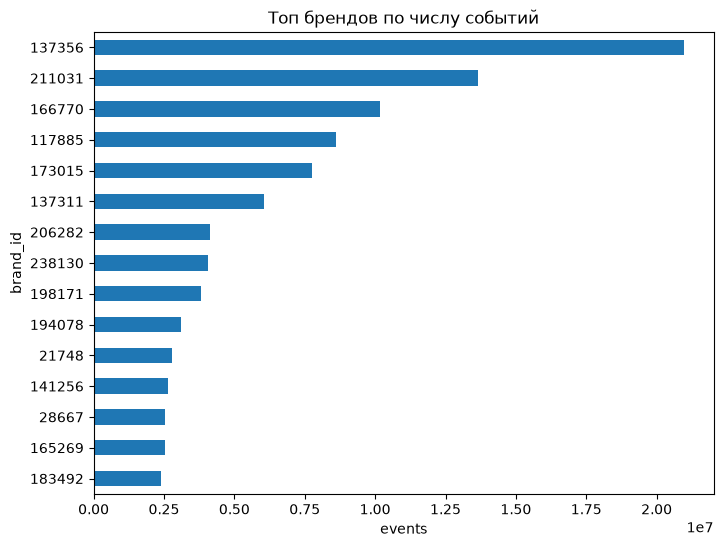

In [13]:
# Топ категорий по числу событий
cat = df_items_stats.groupby("category")["events"].sum().sort_values(ascending=False)
cat.head(15).plot(kind="barh", figsize=(8, 6))
plt.title("Топ категорий по числу событий")
plt.xlabel("events")
plt.gca().invert_yaxis()   # самый популярный — сверху
plt.show()

# Топ брендов по числу событий
brand = df_items_stats.groupby("brand_id")["events"].sum().sort_values(ascending=False)
brand.head(15).plot(kind="barh", figsize=(8, 6))
plt.title("Топ брендов по числу событий")
plt.xlabel("events")
plt.gca().invert_yaxis()
plt.show()


Анализ 
Электроника — абсолютный лидер платформы, собравшая рекордные 30 миллионов событий. Косметика и неклассифицированные товары делят второе место, отставая от лидера почти в два раза и набирая около 17.5 миллионов действий каждая. В данных наблюдается экстремальный дисбаланс, из-за чего последние пять категорий, включая спорт и хобби, практически не генерируют трафик и прижаты к нулю.

**Аномалия: кликов больше, чем показов.** Выше она не видна: `click_rate` считается как
`click / view.replace(0, NaN)`, а гистограммы обрезаны на 1. Оценим масштаб — именно эти
товары удаляет предобработка ниже.

In [26]:
anom = df_items_stats[df_items_stats["click"] > df_items_stats["view"]]
no_view = df_items_stats[df_items_stats["view"] == 0]
anom_users = df_users[df_users["click"] > df_users["view"]]

print(f"товаров с click > view: {len(anom):,} из {len(df_items_stats):,} ({len(anom) / len(df_items_stats):.2%})")
print(f"товаров вообще без показов (view = 0): {len(no_view):,}, из них с кликами: {(no_view['click'] > 0).sum():,}")
print(f"максимальный click_rate: {df_items_stats['click_rate'].max():.1f} у товара, {df_users['click_rate'].max():.1f} у пользователя")
print(f"пользователей с click > view: {len(anom_users):,} из {len(df_users):,} ({len(anom_users) / len(df_users):.2%})")

# самые экстремальные товары — кандидаты на удаление в предобработке ниже
anom.nlargest(10, "click_rate")[["item_id", "view", "click", "click_rate", "category"]]

товаров с click > view: 27,866 из 2,325,409 (1.20%)
товаров вообще без показов (view = 0): 26,004, из них с кликами: 24,377
максимальный click_rate: 19.0 у товара, 11.5 у пользователя
пользователей с click > view: 1,493 из 1,616,763 (0.09%)


,item_id,view,click,click_rate,category
1367095,nfmcg_25142332,1,19,19.0,Miscellaneous Goods (Uncategorized)
582790,nfmcg_16460664,1,10,10.0,"Cosmetics, Personal Care, and Health Maintenance Products"
264962,nfmcg_1293698,1,8,8.0,NaN
2073520,nfmcg_7202498,1,8,8.0,NaN
109770,nfmcg_1121510,2,15,7.5,NaN
183531,nfmcg_12033622,1,7,7.0,NaN
1089796,nfmcg_22077467,1,7,7.0,NaN
1329498,nfmcg_24727854,1,7,7.0,Miscellaneous Goods (Uncategorized)
1537987,nfmcg_27030494,1,7,7.0,Electronic Devices and Gadgets
1547621,nfmcg_27136180,1,7,7.0,NaN


# Предлагаемые проепроцессинг товаров

In [17]:
# Удаляем товары, у которых зафиксирован невозможный click_rate (> 1.0)
df_items_clean = df_items_stats[
    (df_items_stats["click_rate"] <= 1.0) | (df_items_stats["click_rate"].isna())
].copy()

# Логарифмирование аномальных хвостов популярности
# Графики показали, что единичные товары-хиты имеют по 1.3 млн событий,
# улетая в космос от основной массы. Сглаживаем этот экстремальный разброс.
df_items_clean["events_log"] = np.log1p(df_items_clean["events"])
df_items_clean["unique_users_log"] = np.log1p(df_items_clean["unique_users"])


print(f"Было товаров: {df_items_stats.shape[0]:,}")
print(f"Осталось после удаления багов CTR: {df_items_clean.shape[0]:,}")

Было товаров: 2,325,409
Осталось после удаления багов CTR: 2,321,920


# Цена и кликабельность

Каталог даёт цену, категорию и подкатегорию. Смотрим, как конверсия seen→tap
различается по категориям и ценовым сегментам — это заготовка признаков для модели.

In [27]:
# Кликабельность по категориям каталога.
# У заметной доли товаров категории нет (NaN) — считаем их отдельной строкой «—»,
# иначе потеряем эти события целиком
catg = (
    df_items_stats.assign(category=df_items_stats["category"].fillna("—"))
    .groupby("category", observed=True)
    .agg(events=("events", "sum"), views=("view", "sum"), clicks=("click", "sum"))
)
catg["ctr"] = catg["clicks"] / catg["views"]

print(f"товаров без категории: {df_items_stats['category'].isna().mean():.1%}, "
      f"без подкатегории: {df_items_stats['subcategory'].isna().mean():.1%}")
big = catg[catg["views"] > 1_000_000]
print(f"категорий с >1M показов: {len(big)}; CTR от {big['ctr'].min():.2%} до {big['ctr'].max():.2%}")
catg.nlargest(12, "events").round(3)

товаров без категории: 41.6%, без подкатегории: 53.0%
категорий с >1M показов: 13; CTR от 2.36% до 3.66%


,events,views,clicks,ctr
category,,,,
Electronic Devices and Gadgets,29947692,28972198,868161,0.030
Miscellaneous Goods (Uncategorized),17726199,17100654,554719,0.032
"Cosmetics, Personal Care, and Health Maintenance Products",17670698,17150372,429837,0.025
—,17277774,16681682,513643,0.031
"Fashion Accessories, Tech Add-ons, and Style Enhancements",9962645,9630804,289052,0.030
Home/Office Furniture and Interior Decor,8092070,7816620,250681,0.032
Household Electrical Appliances,6496487,6293711,177283,0.028
"Construction and Renovation Materials, Tools, and Equipment",5170524,5013534,143757,0.029
"Outerwear, Casual Apparel, and Specialized Workwear",5101101,4932305,150566,0.031


In [28]:
# Цена: у скольких товаров она есть и как связана с кликабельностью
pr = df_items_stats[df_items_stats["price"].notna() & (df_items_stats["price"] > 0)].copy()
print(f"цена есть у {len(pr):,} товаров из {len(df_items_stats):,} ({len(pr) / len(df_items_stats):.1%})")
print(pr["price"].describe().round(2).to_string())

# CTR по децилям цены (D1 — самые дешёвые)
pr["price_decile"] = pd.qcut(pr["price"], 10, duplicates="drop")
by_price = pr.groupby("price_decile", observed=True).agg(
    views=("view", "sum"), clicks=("click", "sum")
)
by_price["ctr"] = by_price["clicks"] / by_price["views"]
by_price.round(4)

цена есть у 1,299,379 товаров из 2,325,409 (55.9%)
count    1299379.00
mean           2.23
std            1.62
min            0.00
25%            0.95
50%            1.95
75%            3.15
max           10.00


,views,clicks,ctr
price_decile,,,
"(-0.00099822, 0.403]",5158232,160910,0.0312
"(0.403, 0.767]",5992510,162929,0.0272
"(0.767, 1.133]",7772183,242859,0.0312
"(1.133, 1.542]",7854570,217373,0.0277
"(1.542, 1.954]",12824212,413508,0.0322
"(1.954, 2.365]",8617016,258067,0.0299
"(2.365, 2.846]",9663250,293676,0.0304
"(2.846, 3.462]",10453063,317022,0.0303
"(3.462, 4.451]",10140109,330980,0.0326


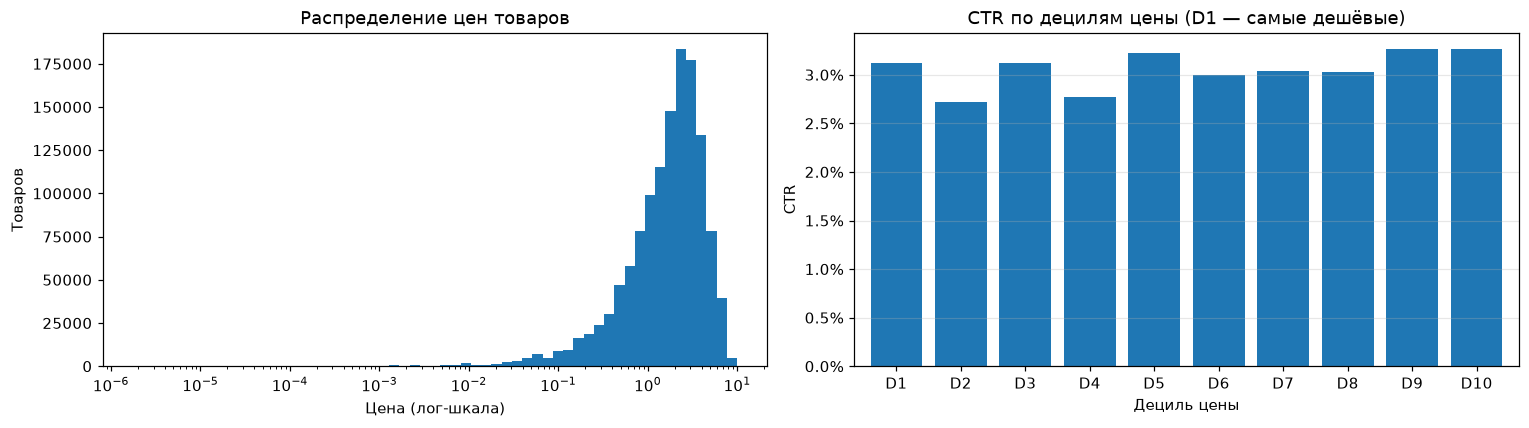

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(pr["price"], bins=np.logspace(np.log10(pr["price"].min()), np.log10(pr["price"].max()), 60))
axes[0].set_xscale("log")
axes[0].set_title("Распределение цен товаров")
axes[0].set_xlabel("Цена (лог-шкала)")
axes[0].set_ylabel("Товаров")

labels = [f"D{i + 1}" for i in range(len(by_price))]
by_price["ctr"].set_axis(labels).plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("CTR по децилям цены (D1 — самые дешёвые)")
axes[1].set_xlabel("Дециль цены")
axes[1].set_ylabel("CTR")
axes[1].tick_params(axis="x", rotation=0)
axes[1].yaxis.set_major_formatter(lambda v, p: f"{v:.1%}")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Анализ событий

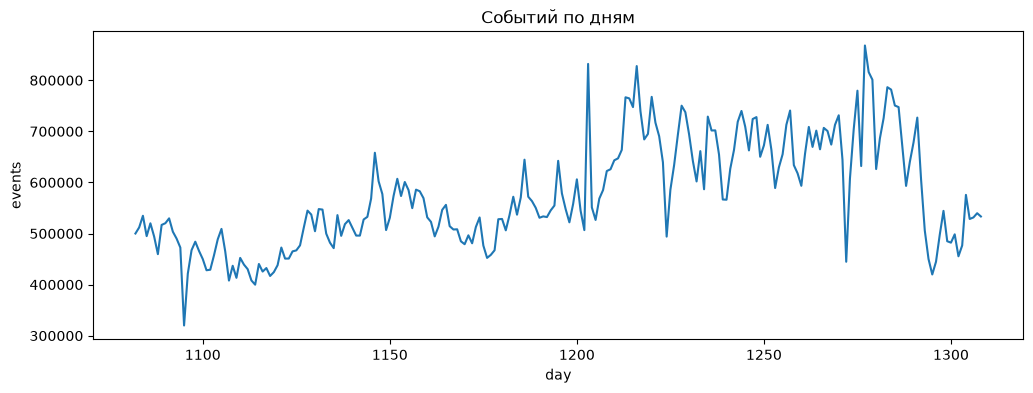

In [ ]:
daily = df.groupby("day").size()
daily.plot(figsize=(12, 4))
plt.title("Событий по дням")
plt.xlabel("day")
plt.ylabel("events")
plt.show()


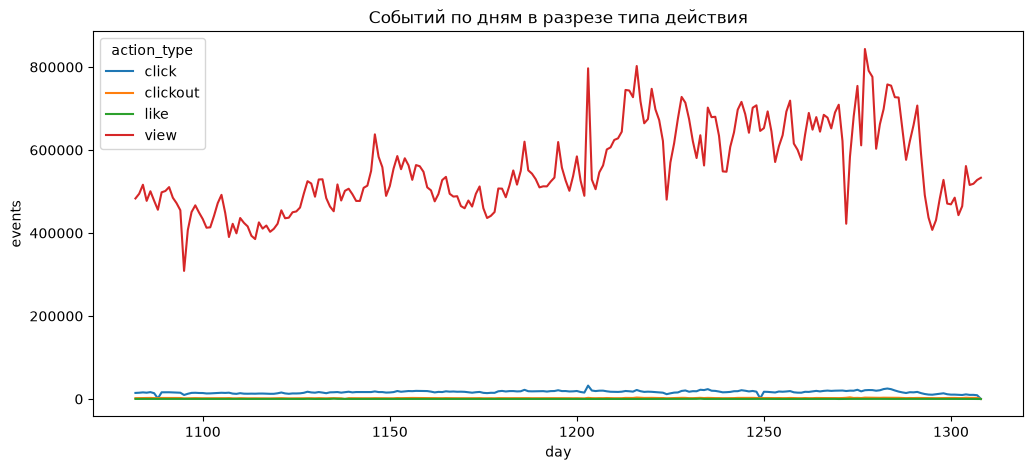

In [18]:
daily_act = df.groupby(["day", "action_type"], observed=True).size().unstack(fill_value=0)

daily_act.plot(figsize=(12, 5))
plt.title("Событий по дням в разрезе типа действия")
plt.xlabel("day")
plt.ylabel("events")
plt.show()


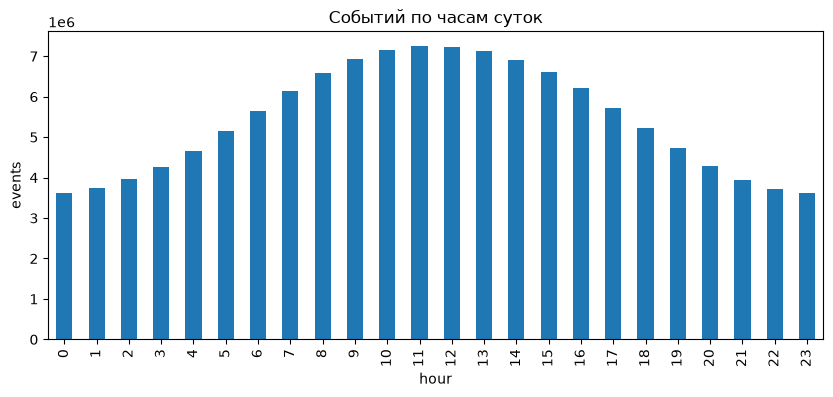

In [19]:
# timestamp — это timedelta[us]; извлекаем час
df["hour"] = df["timestamp"].dt.components["hours"]

hourly = df.groupby("hour").size()

hourly.plot(kind="bar", figsize=(10, 4))
plt.title("Событий по часам суток")
plt.xlabel("hour")
plt.ylabel("events")
plt.show()

In [20]:
# subdomain × action_type (нормируем по строкам)
cross = df.pivot_table(
    index="subdomain", columns="action_type",
    values="item_id", aggfunc="size", fill_value=0, observed=True,
)
cross = cross.div(cross.sum(axis=1), axis=0)

print(cross.round(2))


action_type  click  clickout  view
subdomain                         
catalog       0.04      0.01  0.96
i2i           0.04      0.01  0.95
other         0.01      0.01  0.99
search        0.05      0.02  0.93
u2i           0.03      0.00  0.97


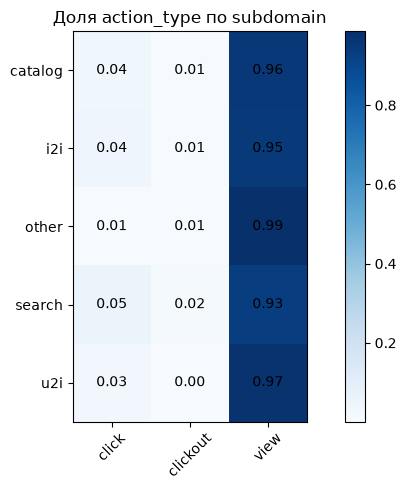

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(cross.values, cmap="Blues")

ax.set_xticks(range(cross.shape[1]), cross.columns, rotation=45)
ax.set_yticks(range(cross.shape[0]), cross.index)

for i in range(cross.shape[0]):
    for j in range(cross.shape[1]):
        ax.text(j, i, f"{cross.values[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im)
plt.title("Доля action_type по subdomain")
plt.tight_layout()
plt.show()


In [22]:
cross_os = df.pivot_table(
    index="os", columns="action_type",
    values="item_id", aggfunc="size", fill_value=0, observed=True,
)
cross_os = cross_os.div(cross_os.sum(axis=1), axis=0)

print(cross_os.round(2))


action_type  click  clickout  like  view
os                                      
android       0.03      0.00   0.0  0.97
ios           0.03      0.00   0.0  0.97
other         0.03      0.01   0.0  0.97


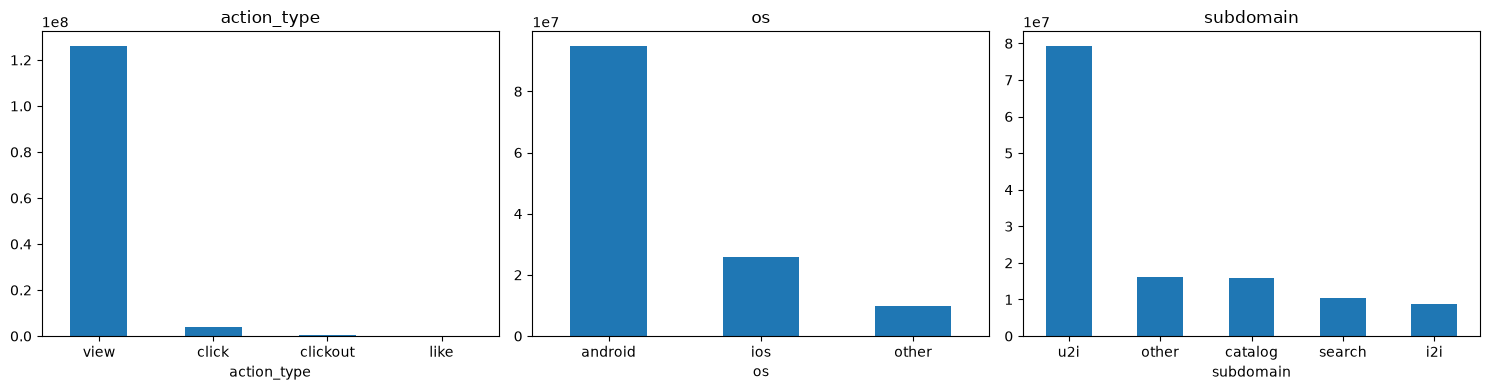

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["action_type"].value_counts().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("action_type")

df["os"].value_counts().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("os")

df["subdomain"].value_counts().plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("subdomain")

plt.tight_layout()
plt.show()

# Конверсия по времени

Насколько однородна целевая конверсия seen→tap во времени: суточный профиль,
дрейф между периодами и целостность отдельных дней (пропуски логирования).
Всё это напрямую влияет на честность временного сплита (test = последние 7 дней).

CTR по дням: в среднем 3.02%, размах 0.03%–4.55%
CTR по часам: минимум 2.92% в 10:00, максимум 3.13% в 0:00
неполных дней (<300k показов при медиане 528,935): 0
полных дней с CTR < 1%: 3 — дни [1088, 1249, 1308] (клики почти пропали)
день 1308 — последний в датасете: клики логировались только до ~3:00
дрейф: первая половина периода ~3.27%, последние 30 дней ~2.44%


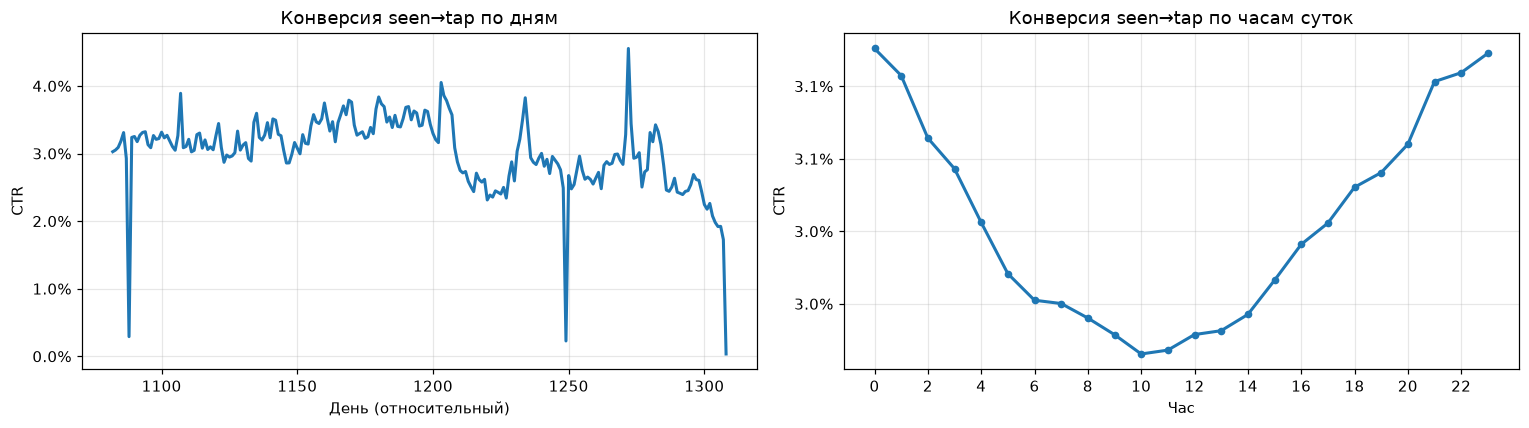

In [30]:
by_day = df.pivot_table(index="day", columns="action_type", values="user_id",
                        aggfunc="size", observed=True)
by_day["ctr"] = by_day["click"] / by_day["view"]

by_hour = df.assign(hour=df["timestamp"].dt.components["hours"]).pivot_table(
    index="hour", columns="action_type", values="user_id", aggfunc="size", observed=True
)
by_hour["ctr"] = by_hour["click"] / by_hour["view"]

print(f"CTR по дням: в среднем {by_day['ctr'].mean():.2%}, размах {by_day['ctr'].min():.2%}–{by_day['ctr'].max():.2%}")
print(f"CTR по часам: минимум {by_hour['ctr'].min():.2%} в {by_hour['ctr'].idxmin()}:00, "
      f"максимум {by_hour['ctr'].max():.2%} в {by_hour['ctr'].idxmax()}:00")

# Целостность дней: неполные (показов сильно меньше медианы) и полные, но с провалом кликов
# целостность логов: все дни полны по показам, но в трёх клики почти пропали
partial = by_day[by_day["view"] < 300_000]
print(f"неполных дней (<300k показов при медиане {by_day['view'].median():,.0f}): {len(partial)}")
low_click = by_day[(by_day["view"] >= 300_000) & (by_day["ctr"] < 0.01)]
print(f"полных дней с CTR < 1%: {len(low_click)} — дни {list(low_click.index)} (клики почти пропали)")
print("день 1308 — последний в датасете: клики логировались только до ~3:00")
half = len(by_day) // 2
print(f"дрейф: первая половина периода ~{by_day['ctr'].iloc[:half].mean():.2%}, "
      f"последние 30 дней ~{by_day['ctr'].iloc[-30:].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(by_day.index, by_day["ctr"], linewidth=2)
axes[0].set_title("Конверсия seen→tap по дням")
axes[0].set_xlabel("День (относительный)")
axes[0].set_ylabel("CTR")
axes[0].yaxis.set_major_formatter(lambda v, p: f"{v:.1%}")
axes[0].grid(alpha=0.3)

axes[1].plot(by_hour.index, by_hour["ctr"], linewidth=2, marker="o", markersize=4)
axes[1].set_title("Конверсия seen→tap по часам суток")
axes[1].set_xlabel("Час")
axes[1].set_ylabel("CTR")
axes[1].set_xticks(range(0, 24, 2))
axes[1].yaxis.set_major_formatter(lambda v, p: f"{v:.1%}")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Cold-start и повторные взаимодействия

Оценим, с чем столкнётся модель при временном сплите (test = последние 7 дней):
сколько пользователей и товаров появляются только в тестовом окне, и какая доля
взаимодействий — повторные показы одной и той же пары пользователь×товар.

In [25]:
# Cold-start: кто из последних 7 дней не встречался в предыдущие ~220 дней,
# и сколько взаимодействий повторяются (матрица ALS суммирует повторы)
CUT = df["day"].max() - 7
is_tail = df["day"] > CUT

head_users = set(df.loc[~is_tail, "user_id"].unique())
head_items = set(df.loc[~is_tail, "item_id"].unique())

tail_users = df.loc[is_tail, "user_id"].unique()
tail_items = df.loc[is_tail, "item_id"].unique()

cold_users = sum(u not in head_users for u in tail_users)
cold_items = sum(i not in head_items for i in tail_items)

# события тестового окна от «холодных» пользователей
tail_user_is_new = ~df.loc[is_tail, "user_id"].isin(head_users).to_numpy()
cold_events = int(tail_user_is_new.sum())

cold_start = pd.DataFrame(
    {
        "всего в test (7 дней)": [len(tail_users), len(tail_items)],
        "из них новые (нет в train)": [cold_users, cold_items],
    },
    index=["пользователи", "товары"],
)
cold_start["доля новых"] = (
    cold_start["из них новые (нет в train)"] / cold_start["всего в test (7 дней)"]
)
print(
    f"событий в test от новых пользователей: {cold_events:,}"
    f" ({cold_events / int(is_tail.sum()):.1%} событий окна)"
)

# Повторные взаимодействия одной пары (user, item)
pair_sizes = df.groupby(["user_id", "item_id"], observed=True).size()
print(f"уникальных пар (user, item): {pair_sizes.size:,} из {len(df):,} событий")
print(f"повторные события: {len(df) - pair_sizes.size:,} ({1 - pair_sizes.size / len(df):.1%})")
print(
    f"пар с единственным событием: {(pair_sizes == 1).mean():.1%} | "
    f"медиана событий на пару: {pair_sizes.median():.0f} | максимум: {pair_sizes.max():,}"
)
cold_start.round(3)

событий в test от новых пользователей: 351,183 (9.6% событий окна)
уникальных пар (user, item): 86,144,047 из 130,447,117 событий
повторные события: 44,303,070 (34.0%)
пар с единственным событием: 76.3% | медиана событий на пару: 1 | максимум: 435


,всего в test (7 дней),из них новые (нет в train),доля новых
пользователи,232035,20229,0.087
товары,384027,89536,0.233


# Анализ пропусков

In [ ]:
def missing_report(df, name=""):
    n = len(df)
    miss = df.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    total_missing = int(df.isna().sum().sum())
    print(f"=== {name}: строк {n}, пропусков {total_missing} "
          f"({total_missing / df.size * 100:.3f}% от всех значений) ===")
    if miss.empty:
        print("пропусков нет\n")
        return
    print(pd.DataFrame({"missing": miss, "share_%": (miss / n * 100).round(2)}), "\n")

missing_report(df_users, "df_users")
missing_report(df, "df (events)")
missing_report(df_items, "df_items (catalog)")

=== df_users: строк 43997878, пропусков 804299 (0.609% от всех значений) ===
                missing  share_%
region           739734     1.68
socdem_cluster    64565     0.15 

=== df (events): строк 130447117, пропусков 41792 (0.005% от всех значений) ===
           missing  share_%
subdomain    41792     0.03 

=== df_items (catalog): строк 2325409, пропусков 2202373 (15.785% от всех значений) ===
             missing  share_%
subcategory  1233023    53.02
category      966395    41.56
price           2882     0.12
embedding         73     0.00 



In [16]:
print(df_users.columns.tolist())
print(df["action_type"].value_counts(dropna=False))


['user_id', 'socdem_cluster', 'region']
action_type
view        126147783
click         3772094
clickout       485448
like            41792
Name: count, dtype: int64


In [17]:
# Считаем действия каждого типа (всегда создаёт view/click/clickout/like)
act = df.pivot_table(
    index="user_id", columns="action_type",
    values="item_id", aggfunc="size", fill_value=0, observed=True,
)

for a in ["view", "click", "clickout", "like"]:
    if a not in act.columns:
        act[a] = 0
act = act[["view", "click", "clickout", "like"]].astype(int)

# Общие агрегаты
g = df.groupby("user_id").agg(
    events=("item_id", "size"),
    unique_items=("item_id", "nunique"),
    active_days=("day", "nunique"),
)

df_users = g.join(act).reset_index()

# Доля переходов (теперь колонки view/click точно есть)
df_users["click_rate"] = df_users["click"] / df_users["view"].replace(0, np.nan)

print("df_users columns:", df_users.columns.tolist())
df_users.head()


df_users columns: ['user_id', 'events', 'unique_items', 'active_days', 'view', 'click', 'clickout', 'like', 'click_rate']


,user_id,events,unique_items,active_days,view,click,clickout,like,click_rate
0,3,6,6,2,6,0,0,0,0.0
1,68,4,4,1,4,0,0,0,0.0
2,76,12,9,2,12,0,0,0,0.0
3,188,22,16,6,22,0,0,0,0.0
4,222,41,31,9,41,0,0,0,0.0


In [18]:
# Describe: только те числовые колонки, что реально есть
num_cols = [c for c in ["events", "unique_items", "active_days",
                        "view", "click", "clickout", "like", "click_rate"]
            if c in df_users.columns]
df_users[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
events,1616763.0,80.684131,160.008893,1.0,9.0,28.0,79.000000,2545.0
unique_items,1616763.0,53.281803,97.266573,1.0,8.0,22.0,56.000000,1866.0
active_days,1616763.0,9.517238,15.470414,1.0,2.0,5.0,11.000000,226.0
view,1616763.0,78.024907,154.333157,0.0,9.0,28.0,77.000000,2482.0
click,1616763.0,2.333115,6.641962,0.0,0.0,0.0,2.000000,379.0
clickout,1616763.0,0.300259,1.646746,0.0,0.0,0.0,0.000000,202.0
like,1616763.0,0.025849,1.165879,0.0,0.0,0.0,0.000000,1151.0
click_rate,1615380.0,0.021544,0.057375,0.0,0.0,0.0,0.027001,11.5


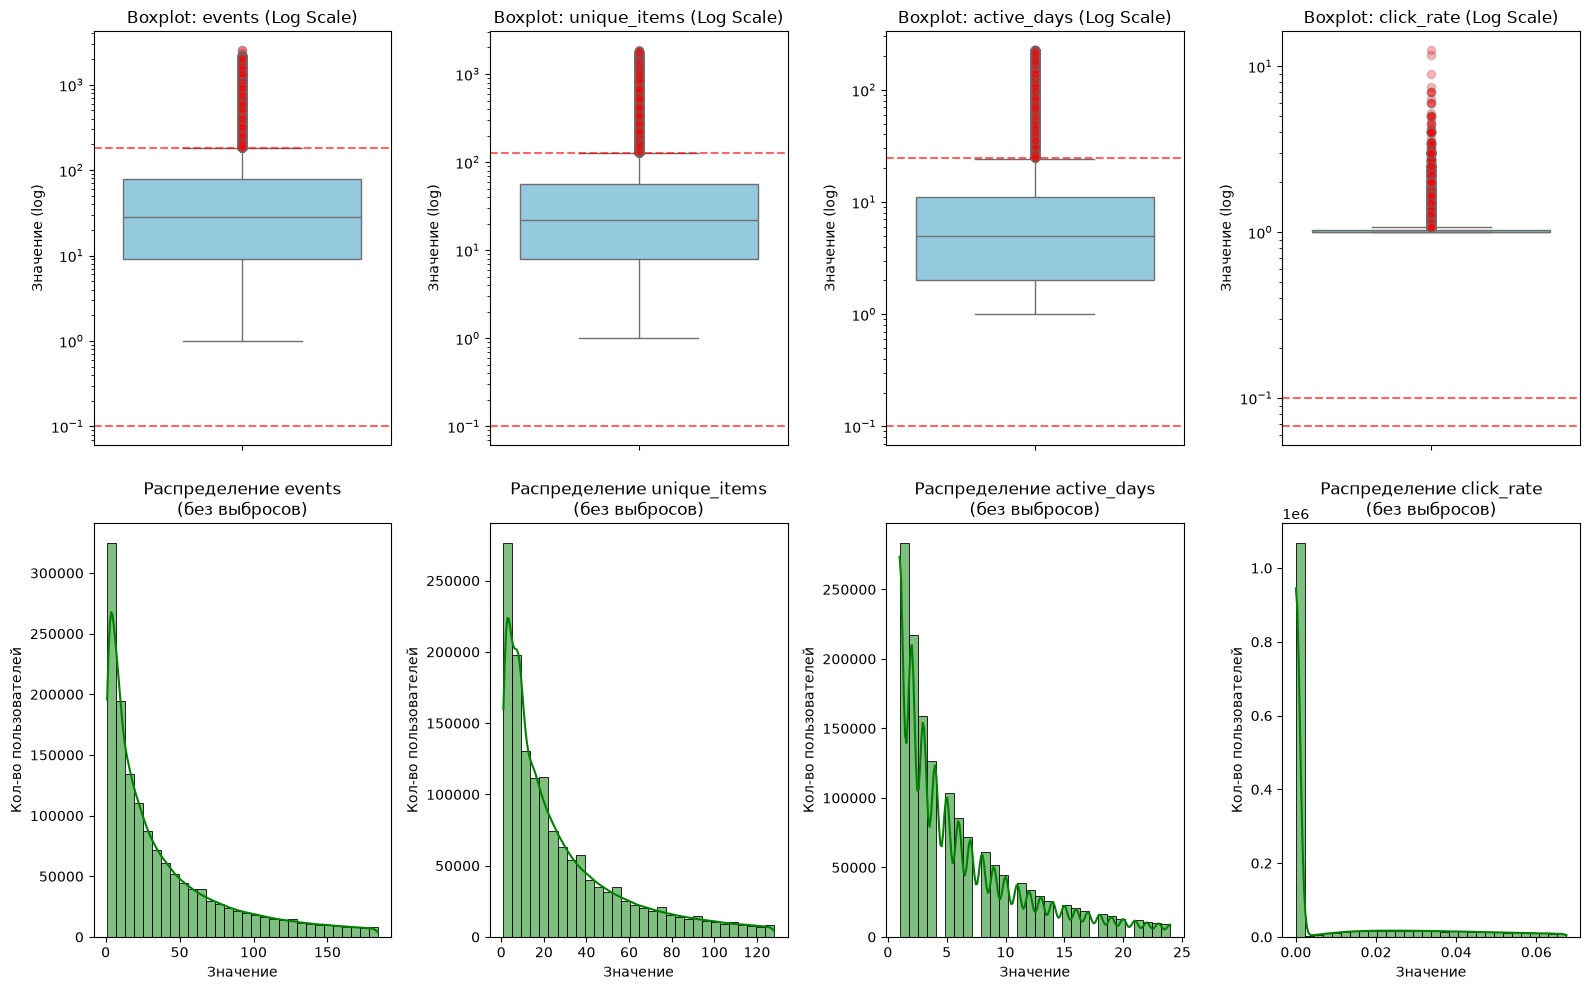

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


columns_to_check = ["events", "unique_items", "active_days", "click_rate"]
existing_columns = [c for c in columns_to_check if c in df_users.columns]

if existing_columns:
    # Делаем сетку: 2 строки (Boxplot и Гистограмма) на N колонок
    fig, axes = plt.subplots(
        2, len(existing_columns), figsize=(4 * len(existing_columns), 10)
    )

    if len(existing_columns) == 1:
        axes = np.reshape(axes, (2, 1))

    for i, c in enumerate(existing_columns):
        s = df_users[c].dropna()
        lo, hi = iqr_bounds(s)

        # ----------------------------------------------------
        # Строка 1: Улучшенный Boxplot с логарифмической шкалой
        # ----------------------------------------------------
        # Добавляем +1 на случай, если в данных есть нули (log(0) не существует)
        s_log = s + 1 if (s <= 0).any() else s

        sns.boxplot(
            y=s_log,
            ax=axes[0, i],
            color="skyblue",
            flierprops={"markerfacecolor": "red", "marker": "o", "alpha": 0.3},
        )
        axes[0, i].set_yscale("log")  # ВКЛЮЧАЕМ ЛОГ-ШКАЛУ
        axes[0, i].set_title(f"Boxplot: {c} (Log Scale)")
        axes[0, i].set_ylabel("Значение (log)")

        # Пересчитываем линии для лог-шкалы
        axes[0, i].axhline(
            y=max(lo, 0.1), color="red", linestyle="--", alpha=0.6
        )
        axes[0, i].axhline(y=hi, color="red", linestyle="--", alpha=0.6)

        # ----------------------------------------------------
        # Строка 2: Гистограмма распределения «нормальных» данных
        # ----------------------------------------------------
        # Показываем только данные до верхней границы IQR, чтобы рассмотреть ядро
        s_normal = s[s <= hi]
        sns.histplot(s_normal, ax=axes[1, i], kde=True, color="green", bins=30)
        axes[1, i].set_title(f"Распределение {c}\n(без выбросов)")
        axes[1, i].set_xlabel("Значение")
        axes[1, i].set_ylabel("Кол-во пользователей")

    plt.tight_layout()
    plt.show()

# Выводы для моделирования

- **Целевая метрика** — конверсия seen→tap: в среднем 3.02%, по часам почти плоская
  (2.92%–3.13%). По дням метрика **не стационарна**: первая половина периода ~3.27%,
  последние 30 дней ~2.44%. Три дня с дефектом логирования кликов: 1088 (CTR 0.29%)
  и 1249 (0.23%) — в train, клики недологированы ~10 раз; 1308 (0.03%) — последний
  день датасета, клики писались только до ~3:00 при полном потоке показов.
  Бейзлайн отбрасывает часы ≥12 этого дня, корректнее — весь день или с 3:00.
  Временной сплит «test = последние 7 дней» остаётся валиден: окно попадает в один режим.
- **Шум данных:** 27,866 товаров (1.20%) с кликами больше показов (максимальный click_rate 19.0)
  и 1,493 пользователя (0.09%) — логическая предобработка выше их удаляет; ещё 26,004 товара
  без единого показа дают NaN в click_rate.
- **Каталог:** категории нет у 41.6% товаров, подкатегории у 53.0% — категориальные признаки
  строим с явным значением «—»; CTR по крупным категориям различается в ~1.6 раза (2.36–3.66%).
  Цена есть у 55.9% товаров, шкала нормированная (~0–10, по сути непрерывная — 1.3М уникальных
  значений); CTR по ценовым децилям различается слабо (2.4–3.4%), самый дорогой дециль кликабельнее.
- **Cold-start:** в test-окне (7 дней) 232,035 пользователей, из них новых (нет в train) 20,229
  (8.7%); товаров — 384,027, новых 89,536 (23.3%) → нужен неперсональный fallback
  (топ популярности по кластеру/глобальный).
- **Повторы:** 34.0% событий — повторные взаимодействия одной пары (user, item), 76.3% пар
  встречаются один раз → в матрице взаимодействий повторы суммируются в вес (ALS),
  для сессионных моделей — фильтровать.
- **Пропуски:** в users.pq нет региона у 1.68%, кластера у 0.15% пользователей; в событиях
  subdomain отсутствует у 0.03% — кластер годится как фича fallback-топа.